# Лабораторная работа 2. Метод ломаных (метод Пиявского)

## Постановка задачи

Дано: функция f(x), липшицева на отрезке [a, b], то есть |f(x) - f(y)| <= L|x - y| для всех x, y из [a, b], и точность eps > 0.

Найти: точку x_best из [a, b], для которой f(x_best) - f* <= eps, где f* это глобальный минимум f на [a, b].

Метод: метод ломаных (Пиявского). Функция оценивается снизу ломаной из конусов f(x_i) - L|x - x_i|, следующая точка вычисляется там, где ломаная ниже всего.

Выход программы: приближенные x_best и f(x_best), число вычислений функции и итераций, время работы, график функции, ломаной и вспомогательных функций.

In [1]:
import time
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from sympy.parsing.sympy_parser import parse_expr, standard_transformations, convert_xor

## 1. Входные данные и разбор функции

Программа принимает строку одномерной функции, концы отрезка и точность eps. Строка превращается в символьное выражение (оно понадобится для вычисления константы Липшица) и в обычную числовую функцию f(x).

In [2]:
func_str = "x + sin(3.14159*x)"
a = -3.0
b = 5.0
eps = 0.01
L_manual = None  # можно задать L вручную, например L_manual = 5

In [3]:
x = sp.Symbol("x", real=True)


def parse_function(func_str):
    f_expr = parse_expr(func_str, local_dict={"x": x},
                        transformations=standard_transformations + (convert_xor,))
    if f_expr.free_symbols - {x}:
        raise ValueError("В функции допустима только переменная x")
    return f_expr, sp.lambdify(x, f_expr, "numpy")


f_expr, f = parse_function(func_str)
print("f(x) =", f_expr)
print("f(a) =", f(a), "  f(b) =", f(b))

f(x) = x + sin(3.14159*x)
f(a) = -3.000007960769381   f(b) = 5.000013267948965


## 2. Оценка константы Липшица

Метод работает, только если |f(x) - f(y)| <= L|x - y| на всем отрезке. Для гладкой функции годится L = max|f'(x)| на [a, b]. Производную берем через sympy, максимум |f'| оцениваем по точкам отрезка и умножаем на запас 1.2, потому что между точками |f'| может быть чуть больше.

**Сетка применяется исключительно для оценки константы Липшица.** Сам минимум ищется по формулам пересечения лучей, вершины ломаной ведутся явно: верхние это вычисленные точки (x_i, f_i), нижние это (x*_i, R_i) (раздел 3).

Ограничение: оценка по сетке надежна, если у функции нет особенностей тоньше шага сетки ((b - a)/10000). Например, у -1/(1 + 1e12(x - 0.413)²) на [0, 1] узкий провал проходит между точками сетки, L получается сильно заниженной, и метод пропускает минимум. В сомнительном случае L задается вручную через L_manual.

Если L занижена, гарантия точности теряется. Если сильно завышена, метод делает лишние вычисления. Для постоянной функции f' = 0, поэтому L ограничена снизу малым числом 1e-12: метод должен получить положительную L.

In [4]:
def lipschitz_constant(f_expr, a, b):
    df = sp.lambdify(x, sp.diff(f_expr, x), "numpy")
    xs = np.linspace(a, b, 10001)  # только для оценки L, не для поиска минимума
    L = 1.2 * np.max(np.abs(df(xs) + 0 * xs))  # + 0*xs: на случай, если f' константа
    return max(L, 1e-12)  # для постоянной функции f' = 0


L = lipschitz_constant(f_expr, a, b) if L_manual is None else L_manual
print("f'(x) =", sp.diff(f_expr, x))
print("L =", L)

f'(x) = 3.14159*cos(3.14159*x) + 1
L = 4.969907999999999


## 3. Построение ломаной: формулы вершин

Для соседних вычисленных точек x1 < x2 со значениями f1, f2 из каждой точки идет луч вниз с наклоном L. Лучи f1 - L(x - x1) и f2 + L(x - x2) пересекаются в нижней вершине ломаной:

- x* = (x1 + x2)/2 + (f1 - f2)/(2L)
- R = (f1 + f2)/2 - L(x2 - x1)/2

R это нижняя оценка функции на [x1, x2]: по условию Липшица f(x) >= R на всем интервале.

In [5]:
def lower_vertex(x1, f1, x2, f2, L):
    x_star = (x1 + x2) / 2 + (f1 - f2) / (2 * L)
    R = (f1 + f2) / 2 - L * (x2 - x1) / 2
    return x_star, R


x_star, R = lower_vertex(a, f(a), b, f(b), L)
print("x* =", x_star, "  R =", R)

x* = 0.19515399191309513   R = -18.879629346410205


## 4. Алгоритм Пиявского

1. Вычисляем f(a) и f(b), точки храним в порядке возрастания x.
2. Для каждой пары соседних точек находим x* и R (раздел 3).
3. Выбираем интервал с минимальным R (при равенстве первый слева).
4. Если f_best - R_min <= eps, останавливаемся: тогда f(x_best) - f* <= eps.
5. Иначе вычисляем f в точке x* этого интервала, вставляем точку между его концами и повторяем.

Число вычислений функции равно len(xs): оно включает f(a) и f(b). Число итераций (пробных точек, добавленных циклом) на 2 меньше.

На каждой итерации R пересчитываются для всех интервалов, поэтому сложность O(n²) по числу точек. Так проще и нагляднее; при eps = 0.01 это сотые доли секунды. При желании ускоряется до O(n log n): пересчитывать только два новых интервала и хранить R в куче.

In [6]:
def piyavsky(f, a, b, L, eps):
    if not a < b:
        raise ValueError("Должно выполняться a < b")
    if eps <= 0 or L <= 0:
        raise ValueError("eps и L должны быть положительными")

    start = time.perf_counter()
    xs = [a, b]
    fs = [float(f(a)), float(f(b))]
    while True:
        vertices = [lower_vertex(xs[i], fs[i], xs[i + 1], fs[i + 1], L) for i in range(len(xs) - 1)]
        Rs = [R for _, R in vertices]
        i = int(np.argmin(Rs))  # первый интервал с минимальным R
        if min(fs) - Rs[i] <= eps:
            break
        x_new = vertices[i][0]
        if not xs[i] < x_new < xs[i + 1]:
            raise ValueError("x* вышла за интервал: константа L занижена")
        xs.insert(i + 1, x_new)
        fs.insert(i + 1, float(f(x_new)))
    elapsed = time.perf_counter() - start

    k = int(np.argmin(fs))
    return xs[k], fs[k], xs, fs, elapsed


x_best, f_best, xs, fs, elapsed = piyavsky(f, a, b, L, eps)
print(f"x_best = {x_best:.6f}   f(x_best) = {f_best:.6f}")
print("Вычислений функции:", len(xs), "  итераций:", len(xs) - 2)
print(f"Время: {elapsed:.4f} с")

x_best = -2.603425   f(x_best) = -3.551104
Вычислений функции: 53   итераций: 51
Время: 0.0015 с


## 5. Верификация на функциях с известным решением

- f = x² на [-1, 2], L = 4 (это max|2x|): минимум f(0) = 0. При eps = 0.5 ожидаем 9 вычислений, при eps = 0.1 ожидаем 23.
- f = sin(3x) на [0, 6]: истинная L = 3, минимум -1. С L = 1 (занижена) метод останавливается рано и с неверным ответом.

In [7]:
square = lambda t: t ** 2
for e in (0.5, 0.1):
    xb, fb, pts, _, _ = piyavsky(square, -1, 2, 4, e)
    print(f"x^2, eps = {e}: x_best = {xb:.4f}, f = {fb:.4f}, вычислений: {len(pts)}, итераций: {len(pts) - 2}")

for L_test in (3, 1):
    xb, fb, pts, _, _ = piyavsky(lambda t: np.sin(3 * t), 0, 6, L_test, 0.1)
    print(f"sin(3x), L = {L_test}: x_best = {xb:.4f}, f = {fb:.4f}, вычислений: {len(pts)}, итераций: {len(pts) - 2}")

x^2, eps = 0.5: x_best = -0.0843, f = 0.0071, вычислений: 9, итераций: 7
x^2, eps = 0.1: x_best = -0.0061, f = 0.0000, вычислений: 23, итераций: 21
sin(3x), L = 3: x_best = 3.6769, f = -0.9994, вычислений: 25, итераций: 23
sin(3x), L = 1: x_best = 6.0000, f = -0.7510, вычислений: 7, итераций: 5


## 6. Визуализация результатов

- f(x) рисуем по частым точкам: они нужны только для картинки.
- Вспомогательные функции g_i(x) = f_i - L|x - x_i| это «конусы» из каждой вычисленной точки (серые).
- Ломаная F(x) = max_i g_i(x) строится по своим вершинам: верхние вершины это вычисленные точки (x_i, f_i), нижние это (x*_i, R_i) из раздела 3.

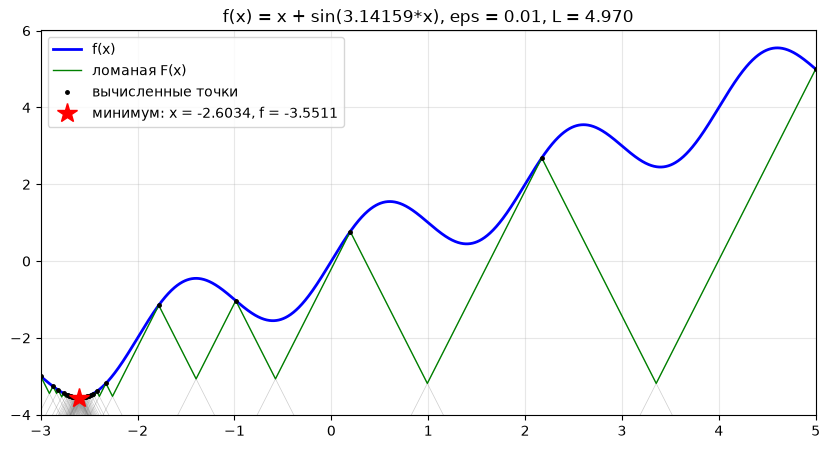

In [8]:
def plot_result(f, a, b, L, xs, fs, x_best, f_best, title):
    px, py = [xs[0]], [fs[0]]  # вершины ломаной слева направо
    for i in range(len(xs) - 1):
        x_star, R = lower_vertex(xs[i], fs[i], xs[i + 1], fs[i + 1], L)
        px += [x_star, xs[i + 1]]
        py += [R, fs[i + 1]]

    grid = np.linspace(a, b, 2000)  # только для рисования графика
    fg = f(grid) + 0 * grid
    plt.figure(figsize=(10, 5))
    for xi, fi in zip(xs, fs):
        plt.plot([a, xi, b], [fi - L * (xi - a), fi, fi - L * (b - xi)], color="gray", lw=0.5, alpha=0.4)
    plt.plot(grid, fg, "b", lw=2, label="f(x)")
    plt.plot(px, py, "g", lw=1, label="ломаная F(x)")
    plt.plot(xs, fs, "k.", ms=5, label="вычисленные точки")
    plt.plot(x_best, f_best, "r*", ms=15, label=f"минимум: x = {x_best:.4f}, f = {f_best:.4f}")
    span = max(fg) - min(py)
    plt.ylim(min(py) - 0.05 * span, max(fg) + 0.05 * span)
    plt.xlim(a, b)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


plot_result(f, a, b, L, xs, fs, x_best, f_best, f"f(x) = {func_str}, eps = {eps}, L = {L:.3f}")

## 7. Демонстрация: функции Растригина и Экли

Функция `solve` собирает все разделы: разбор строки, L, метод, вывод результата и график. Здесь L вычисляется автоматически (раздел 2). Отрезки взяты несимметричными: на симметричном отрезке первая же точка x* попадает ровно в 0, то есть в глобальный минимум.

- Растригин: x² - 10cos(2πx) + 10, глобальный минимум f(0) = 0, на отрезке много локальных минимумов.
- Экли: -20exp(-0.2|x|) - exp(cos(2πx)) + 20 + e, глобальный минимум f(0) = 0.

f(x) = x**2 - 10*cos(2*pi*x) + 10,  [a, b] = [-2.3, 4.1],  eps = 0.01,  L = 83.199
x_best = -0.000022   f(x_best) = 0.000000
Вычислений функции: 171   итераций: 169
Время: 0.0118 с


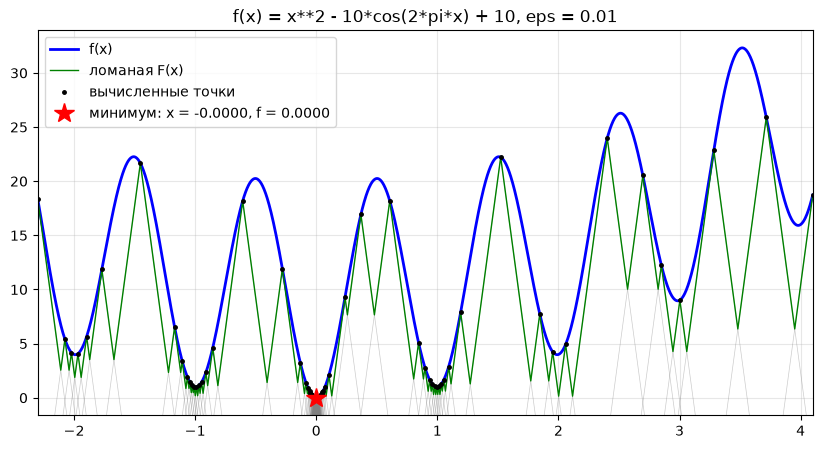

In [9]:
def solve(func_str, a, b, eps, L_manual=None):
    f_expr, f = parse_function(func_str)
    L = lipschitz_constant(f_expr, a, b) if L_manual is None else L_manual
    x_best, f_best, xs, fs, elapsed = piyavsky(f, a, b, L, eps)
    print(f"f(x) = {func_str},  [a, b] = [{a}, {b}],  eps = {eps},  L = {L:.3f}")
    print(f"x_best = {x_best:.6f}   f(x_best) = {f_best:.6f}")
    print("Вычислений функции:", len(xs), "  итераций:", len(xs) - 2)
    print(f"Время: {elapsed:.4f} с")
    plot_result(f, a, b, L, xs, fs, x_best, f_best, f"f(x) = {func_str}, eps = {eps}")


solve("x**2 - 10*cos(2*pi*x) + 10", -2.3, 4.1, 0.01)

f(x) = -20*exp(-0.2*abs(x)) - exp(cos(2*pi*x)) + 20 + E,  [a, b] = [-3.7, 2.4],  eps = 0.01,  L = 15.661
x_best = -0.000341   f(x_best) = 0.001369
Вычислений функции: 27   итераций: 25
Время: 0.0004 с


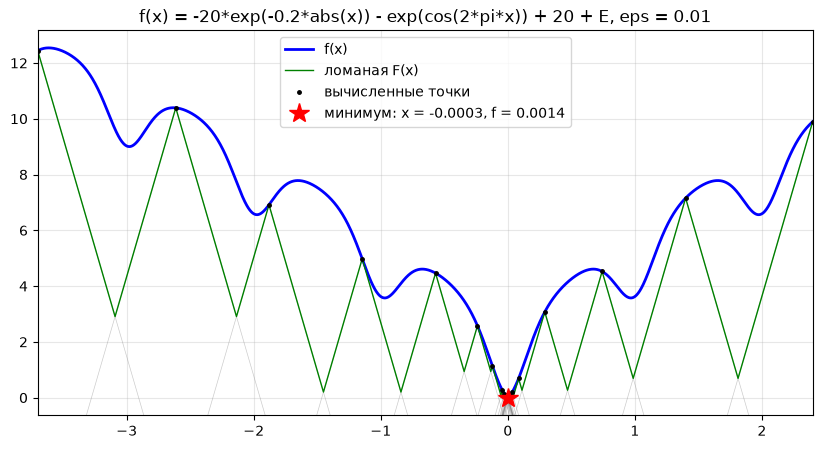

In [10]:
solve("-20*exp(-0.2*abs(x)) - exp(cos(2*pi*x)) + 20 + E", -3.7, 2.4, 0.01)

Влияние eps и L на число вычислений (Растригин на [-2.3, 4.1]): чем меньше eps и чем больше L, тем больше вычислений. Здесь L задается вручную:

- 71.03 это аналитическая оценка: |f'| = |2x + 20π sin(2πx)| <= 2·max(|a|, |b|) + 20π;
- 83.2 это автоматическая оценка из раздела 2, она использовалась в демонстрации выше (171 вычисление при eps = 0.01);
- 150 это сильно завышенная L.

Истинное значение max|f'| на этом отрезке около 69.3, поэтому все три L допустимы и ответ везде верный; отличается только число вычислений.

In [11]:
rastrigin = parse_function("x**2 - 10*cos(2*pi*x) + 10")[1]
for L_test in (71.03, 83.2, 150):
    for e in (0.1, 0.01):
        xb, fb, pts, _, _ = piyavsky(rastrigin, -2.3, 4.1, L_test, e)
        print(f"L = {L_test:6}, eps = {e:4}: вычислений {len(pts):4}, итераций {len(pts) - 2:4}, x_best = {xb:.5f}, f = {fb:.6f}")

L =  71.03, eps =  0.1: вычислений   59, итераций   57, x_best = -0.00063, f = 0.000080


L =  71.03, eps = 0.01: вычислений  153, итераций  151, x_best = 0.00004, f = 0.000000
L =   83.2, eps =  0.1: вычислений   85, итераций   83, x_best = 0.00037, f = 0.000027
L =   83.2, eps = 0.01: вычислений  171, итераций  169, x_best = -0.00002, f = 0.000000
L =    150, eps =  0.1: вычислений  151, итераций  149, x_best = -0.00025, f = 0.000012
L =    150, eps = 0.01: вычислений  303, итераций  301, x_best = 0.00001, f = 0.000000


## Выводы

- Метод находит глобальный, а не локальный минимум: на Растригине и Экли с множеством локальных минимумов найдена точка около x = 0.
- Минимум ломаной находится по формулам пересечения конусов (x*, R), без перебора.
- При остановке гарантируется f(x_best) - f* <= eps, если L не меньше истинной константы Липшица.
- Число вычислений растет при уменьшении eps и увеличении L. При заниженной L гарантия теряется.
- Автоматическая оценка L по сетке надежна для функций без особенностей тоньше шага сетки; иначе L нужно задать вручную.